In [2]:
# !wget http://www.inf.ufpr.br/vri/databases/BreaKHis_v1.tar.gz -O dataset.tar.gz

In [3]:
# ! tar -xzvf /kaggle/working/dataset.tar.gz

In [4]:
# ! rm /kaggle/working/dataset.tar.gz

## Separating the Directories

In [6]:
import os
import shutil
import random
from tqdm import tqdm

def split_and_organize_by_categories(input_dir, output_dir, train_ratio=0.9, test_ratio=0.05, val_ratio=0.05):
    random.seed(42)  # For reproducibility

    # Create output directories
    for split in ["train", "test", "validation"]:
        os.makedirs(os.path.join(output_dir, split), exist_ok=True)

    # Iterate through all tumor categories
    for malignancy in ["benign", "malignant"]:
        malignancy_path = os.path.join(input_dir, malignancy, "SOB")

        if not os.path.exists(malignancy_path):
            print(f"Directory not found: {malignancy_path}")
            continue

        for tumor_category in os.listdir(malignancy_path):
            tumor_path = os.path.join(malignancy_path, tumor_category)
            if not os.path.isdir(tumor_path):
                continue

            # Collect all images (ignore magnification)
            all_files = []
            for subdir, _, files in os.walk(tumor_path):
                all_files.extend([os.path.join(subdir, f) for f in files])

            # Shuffle and split files
            random.shuffle(all_files)
            total_files = len(all_files)
            train_files = all_files[:int(total_files * train_ratio)]
            test_files = all_files[int(total_files * train_ratio):int(total_files * (train_ratio + test_ratio))]
            val_files = all_files[int(total_files * (train_ratio + test_ratio)):]

            # Copy files to respective directories with progress bar
            for split, split_files in zip(["train", "test", "validation"], [train_files, test_files, val_files]):
                dest_dir = os.path.join(output_dir, split, tumor_category)
                os.makedirs(dest_dir, exist_ok=True)

                for file in tqdm(split_files, desc=f"Processing {tumor_category} ({split})", unit="files"):
                    shutil.copy(file, os.path.join(dest_dir, os.path.basename(file)))

    print("Dataset successfully organized by categories!")

# Define input and output directories
input_dir = "/kaggle/working/BreaKHis_v1/histology_slides/breast"
output_dir = "/kaggle/working/classification_dataset_by_category"

# Run the function
split_and_organize_by_categories(input_dir, output_dir)

Processing papillary_carcinoma (validation): 100%|██████████| 28/28 [00:00<00:00, 1651.53files/s]

Dataset successfully organized by categories!


In [1]:
! tree /kaggle/working/classification_dataset_by_category -d

/kaggle/working/classification_dataset_by_category
|-- test
|   |-- adenosis
|   |-- ductal_carcinoma
|   |-- fibroadenoma
|   |-- lobular_carcinoma
|   |-- mucinous_carcinoma
|   |-- papillary_carcinoma
|   |-- phyllodes_tumor
|   `-- tubular_adenoma
|-- train
|   |-- adenosis
|   |-- ductal_carcinoma
|   |-- fibroadenoma
|   |-- lobular_carcinoma
|   |-- mucinous_carcinoma
|   |-- papillary_carcinoma
|   |-- phyllodes_tumor
|   `-- tubular_adenoma
`-- validation
    |-- adenosis
    |-- ductal_carcinoma
    |-- fibroadenoma
    |-- lobular_carcinoma
    |-- mucinous_carcinoma
    |-- papillary_carcinoma
    |-- phyllodes_tumor
    `-- tubular_adenoma

27 directories


In [39]:
import os
import pandas as pd
from typing import List, Union

# Define the path to the train folder
train_path = "/kaggle/working/classification_dataset_by_category/train"
test_path = "/kaggle/working/classification_dataset_by_category/test"
validation_path = "/kaggle/working/classification_dataset_by_category/validation"
data_paths = [train_path, validation_path]

def make_dataframe(paths: Union[List, str]):
    datas = []
    for path in paths:
        for folder in os.listdir(path):
            folder_class = os.path.join(path, folder)
            if os.path.isdir(folder_class):
                images = os.listdir(folder_class)
                for image in images:
                    image_path = os.path.join(folder_class, image)
                    data = {
                        'Image Path': image_path,
                        'Class': folder.title()
                    }
                    datas.append(data)
    df = pd.DataFrame(datas)
    return df

df = make_dataframe(data_paths)

In [40]:
df.describe()

,Image Path,Class
count,7513,7513
unique,7513,8
top,/kaggle/working/classification_dataset_by_cate...,Ductal_Carcinoma
freq,1,3278


In [4]:
from kaggle_secrets import UserSecretsClient
user_secrets = UserSecretsClient()
secret_value_0 = user_secrets.get_secret("HUGGINGFACE_HUB_API_KEY")

In [5]:
from huggingface_hub import login

# Use the token from the environment variable
login(token=secret_value_0)

In [6]:
import numpy as np
import tensorflow as tf
from huggingface_hub import from_pretrained_keras
from io import BytesIO
from PIL import Image
import matplotlib.pyplot as plt

In [7]:
loaded_model = from_pretrained_keras("google/path-foundation")
infer = loaded_model.signatures["serving_default"]

Fetching 8 files:   0%|          | 0/8 [00:00<?, ?it/s]

.gitattributes:   0%|          | 0.00/1.59k [00:00<?, ?B/s]

Test.png:   0%|          | 0.00/208k [00:00<?, ?B/s]

variables/variables.index:   0%|          | 0.00/3.64k [00:00<?, ?B/s]

README.md:   0%|          | 0.00/12.8k [00:00<?, ?B/s]

keras_metadata.pb:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

saved_model.pb:   0%|          | 0.00/3.52M [00:00<?, ?B/s]

variables.data-00000-of-00001:   0%|          | 0.00/110M [00:00<?, ?B/s]

fingerprint.pb:   0%|          | 0.00/58.0 [00:00<?, ?B/s]

In [47]:
import os
import numpy as np
import pandas as pd
from PIL import Image
import tensorflow as tf
from huggingface_hub import from_pretrained_keras
from typing import List
from tqdm import tqdm

# 1. Load the Pretrained Hugging Face Model
def _load_huggingface_model() -> tf.keras.Model:
    """Returns a model loaded from Hugging Face."""
    if 'loaded_model' not in globals():
        global loaded_model
        loaded_model = from_pretrained_keras(
            'google/path-foundation', compile=False
        )
    return loaded_model

# Load the model
model = _load_huggingface_model()

# 2. Preprocess Images
def preprocess_image(image_path: str) -> np.ndarray:
    """Loads and preprocesses an image from the given path."""
    try:
        image = Image.open(image_path).convert("RGB")  # Ensure RGB format
        image = image.resize((224, 224))  # Resize to match model's expected input size
        image_array = np.array(image) / 255.0  # Normalize to [0, 1]
        return np.expand_dims(image_array, axis=0)  # Add batch dimension
    except Exception as e:
        print(f"Error processing image {image_path}: {e}")
        return None

# 3. Generate Embeddings
def generate_embedding(image_path: str, model: tf.keras.Model) -> np.ndarray:
    """Generates embeddings for a single image using the Path Foundation model."""
    preprocessed_image = preprocess_image(image_path)
    if preprocessed_image is None:
        return None
    try:
        result = model.signatures['serving_default'](
            tf.constant(preprocessed_image, dtype=tf.float32)
        )
        return result['output_0'].numpy().flatten()  # Flatten the embedding
    except Exception as e:
        print(f"Error generating embedding for image {image_path}: {e}")
        return None

# 4. Add Embeddings to DataFrame
def add_embeddings_to_dataframe(df: pd.DataFrame, image_col: str, model: tf.keras.Model) -> pd.DataFrame:
    """Generates embeddings for images in the dataframe and adds them as a new column."""
    embeddings = []
    for image_path in tqdm(df[image_col], desc='Generating Emebddings', unit='image'):
        embedding = generate_embedding(image_path, model)
        embeddings.append(embedding)
    
    # Add embeddings to the dataframe
    df['Embeddings'] = embeddings
    return df

In [ ]:
# Add embeddings to the dataframe
df_with_embeddings = add_embeddings_to_dataframe(df, 'Image Path', model)

In [9]:
df_with_embeddings.head()

,Image Path,Class,Embeddings
0,/kaggle/working/classification_dataset_by_cate...,Tubular_Adenoma,"[0.39216995, -4.808557, 0.08034734, -0.9603019..."
1,/kaggle/working/classification_dataset_by_cate...,Tubular_Adenoma,"[2.0367708, 2.848889, 0.568601, 2.274048, -1.3..."
2,/kaggle/working/classification_dataset_by_cate...,Tubular_Adenoma,"[-0.2208986, -5.2324467, 1.0484952, 0.07717633..."
3,/kaggle/working/classification_dataset_by_cate...,Tubular_Adenoma,"[2.6047382, -0.12357947, -0.20428877, -1.33520..."
4,/kaggle/working/classification_dataset_by_cate...,Tubular_Adenoma,"[2.574098, 4.385789, 0.5838923, 0.021493316, 1..."


## Visualising the clustering patterns and analyse it

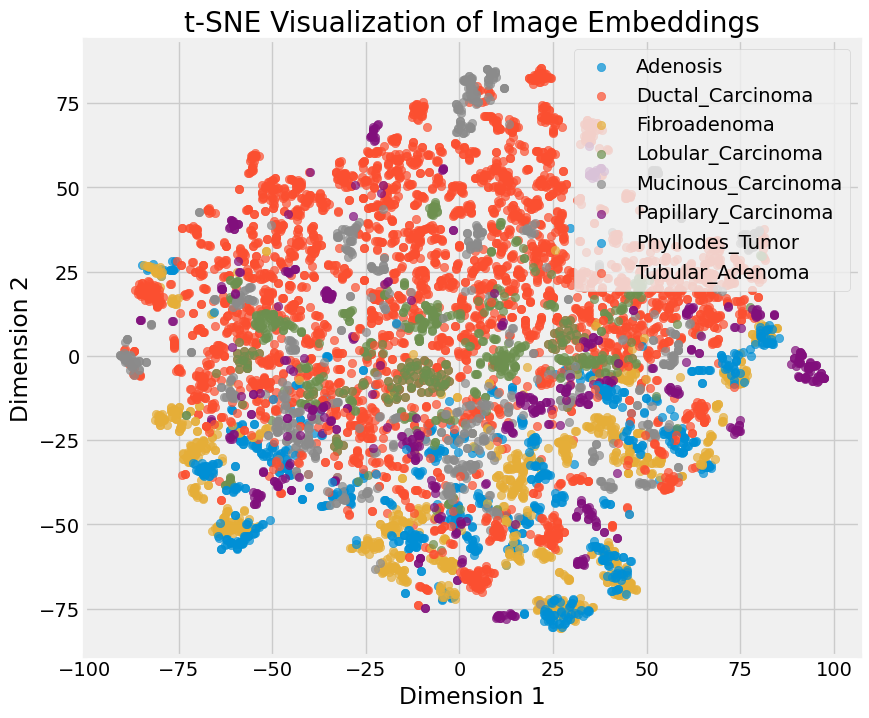

In [10]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

# Convert embeddings to a NumPy array
embeddings = np.vstack(df_with_embeddings['Embeddings'].dropna())
labels = df_with_embeddings['Class']

# Reduce to 2 dimensions using t-SNE
tsne = TSNE(n_components=2, random_state=42)
embeddings_2d = tsne.fit_transform(embeddings)

# Plot
plt.figure(figsize=(10, 8))
plt.style.use('fivethirtyeight')
for label in np.unique(labels):
    idx = labels == label
    plt.scatter(embeddings_2d[idx, 0], embeddings_2d[idx, 1], label=label, alpha=0.7)
plt.title('t-SNE Visualization of Image Embeddings')
plt.xlabel('Dimension 1')
plt.ylabel('Dimension 2')
plt.legend()
plt.show()

/opt/conda/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


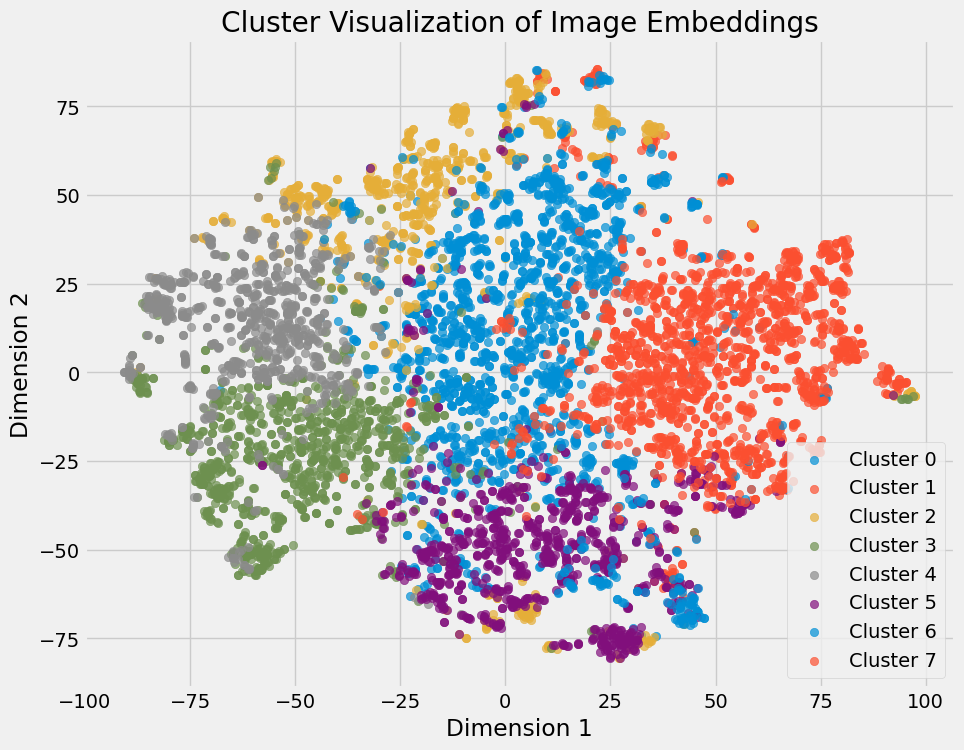

In [11]:
from sklearn.cluster import KMeans

# Apply K-Means clustering
n_clusters = len(np.unique(labels))  # Assume number of clusters equals number of classes
kmeans = KMeans(n_clusters=n_clusters, random_state=42)
clusters = kmeans.fit_predict(embeddings)

# Add cluster labels to the dataframe
df_with_embeddings['Cluster'] = clusters

# Plot clusters
plt.figure(figsize=(10, 8))
for cluster in np.unique(clusters):
    idx = clusters == cluster
    plt.scatter(embeddings_2d[idx, 0], embeddings_2d[idx, 1], label=f'Cluster {cluster}', alpha=0.7)
plt.title('Cluster Visualization of Image Embeddings')
plt.xlabel('Dimension 1')
plt.ylabel('Dimension 2')
plt.legend()
plt.show()

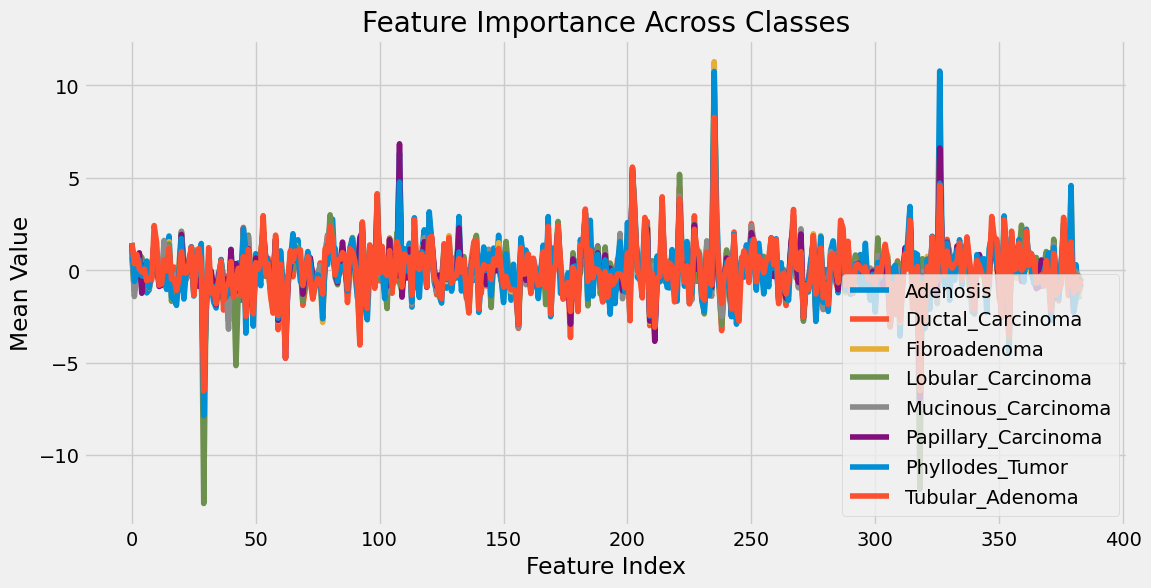

In [12]:
feature_means = df_with_embeddings.groupby('Class')['Embeddings'].apply(
    lambda x: np.mean(np.vstack(x), axis=0)
)
plt.figure(figsize=(12, 6))
for class_label in feature_means.index:
    plt.plot(feature_means.loc[class_label], label=class_label)
plt.title('Feature Importance Across Classes')
plt.xlabel('Feature Index')
plt.ylabel('Mean Value')
plt.legend()
plt.show()


In [13]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import numpy as np

# Extract features and labels
X = np.vstack(df_with_embeddings['Embeddings'].dropna())  # Embeddings as features
y = df_with_embeddings['Class']  # Labels

# Encode labels if they are categorical
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.05, random_state=42)


In [14]:
from sklearn.linear_model import LogisticRegression

# Initialize the logistic regression model
logistic_model = LogisticRegression(max_iter=1000, random_state=42)

# Train the model
logistic_model.fit(X_train, y_train)

/opt/conda/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(max_iter=1000, random_state=42)

In [19]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# Predict on the test set
y_pred = logistic_model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.2f}")

# Detailed classification report
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))

Accuracy: 0.83
Classification Report:
                     precision    recall  f1-score   support

           Adenosis       0.76      0.79      0.78        24
   Ductal_Carcinoma       0.87      0.85      0.86       155
       Fibroadenoma       0.88      0.94      0.91        49
  Lobular_Carcinoma       0.60      0.67      0.63        27
 Mucinous_Carcinoma       0.68      0.78      0.73        36
Papillary_Carcinoma       0.86      0.81      0.83        31
    Phyllodes_Tumor       0.95      0.91      0.93        23
    Tubular_Adenoma       0.92      0.77      0.84        31

           accuracy                           0.83       376
          macro avg       0.82      0.82      0.81       376
       weighted avg       0.84      0.83      0.83       376



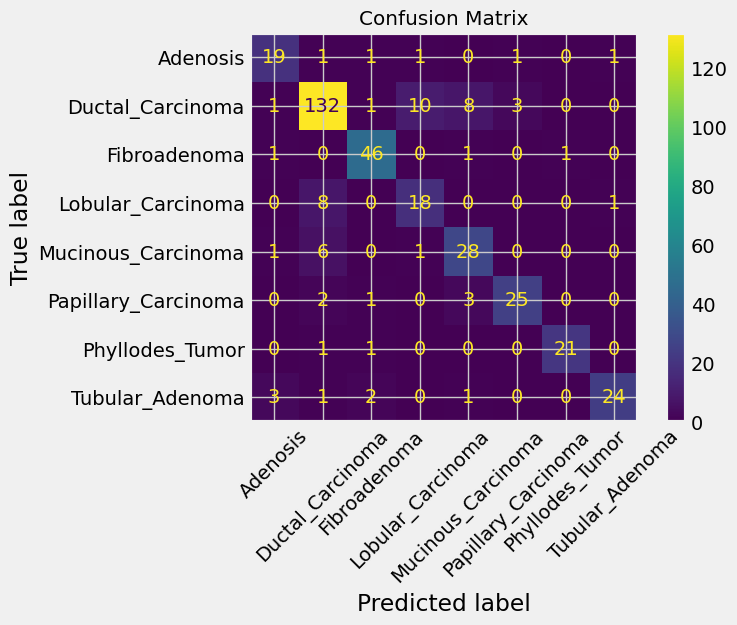

In [20]:
def plot_confusion_matrix(model, X_test, y_test, label_encoder):
    # Compute confusion matrix
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    
    # Display the confusion matrix with angled x-axis labels
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_encoder.classes_)
    disp.plot()
    plt.style.use('ggplot')
    plt.title('Confusion Matrix')
    plt.xticks(rotation=45)
    plt.show()

plot_confusion_matrix(logistic_model, X_test, y_test, label_encoder)

Random Forest Accuracy: 0.6888297872340425
Random Forest Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.46      0.63        24
           1       0.60      0.99      0.75       155
           2       0.76      0.76      0.76        49
           3       0.78      0.26      0.39        27
           4       1.00      0.44      0.62        36
           5       1.00      0.26      0.41        31
           6       1.00      0.57      0.72        23
           7       0.88      0.45      0.60        31

    accuracy                           0.69       376
   macro avg       0.88      0.52      0.61       376
weighted avg       0.78      0.69      0.66       376



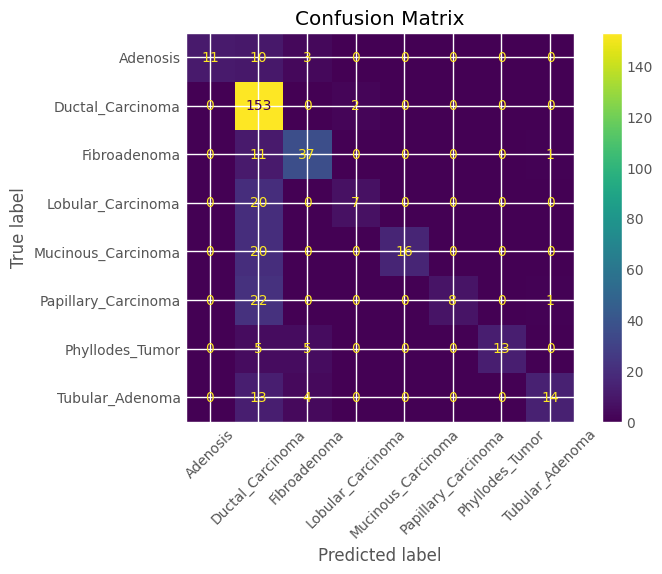

In [21]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Initialize and train the RandomForest model
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Make predictions
y_pred_rf = rf_model.predict(X_test)

# Evaluate the model
print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Random Forest Classification Report:\n", classification_report(y_test, y_pred_rf))
plot_confusion_matrix(rf_model, X_test, y_test, label_encoder)

SVM Accuracy: 0.8537234042553191
SVM Classification Report:
               precision    recall  f1-score   support

           0       0.71      0.92      0.80        24
           1       0.86      0.90      0.88       155
           2       0.92      0.92      0.92        49
           3       0.64      0.59      0.62        27
           4       0.79      0.75      0.77        36
           5       0.96      0.74      0.84        31
           6       0.96      0.96      0.96        23
           7       0.93      0.84      0.88        31

    accuracy                           0.85       376
   macro avg       0.85      0.83      0.83       376
weighted avg       0.86      0.85      0.85       376



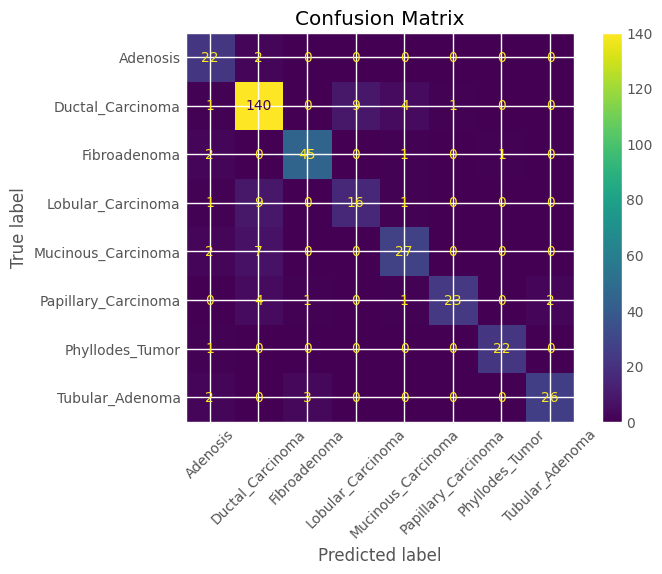

In [22]:
from sklearn.svm import SVC

svm_model = SVC(kernel='linear', probability=True, random_state=42)
svm_model.fit(X_train, y_train)

y_pred_svm = svm_model.predict(X_test)

print("SVM Accuracy:", accuracy_score(y_test, y_pred_svm))
print("SVM Classification Report:\n", classification_report(y_test, y_pred_svm))
plot_confusion_matrix(svm_model, X_test, y_test, label_encoder)

KNN Accuracy: 0.8617021276595744
KNN Classification Report:
               precision    recall  f1-score   support

           0       0.75      0.88      0.81        24
           1       0.87      0.92      0.89       155
           2       0.87      0.96      0.91        49
           3       0.64      0.52      0.57        27
           4       0.83      0.83      0.83        36
           5       0.93      0.84      0.88        31
           6       0.95      0.83      0.88        23
           7       1.00      0.81      0.89        31

    accuracy                           0.86       376
   macro avg       0.85      0.82      0.83       376
weighted avg       0.86      0.86      0.86       376



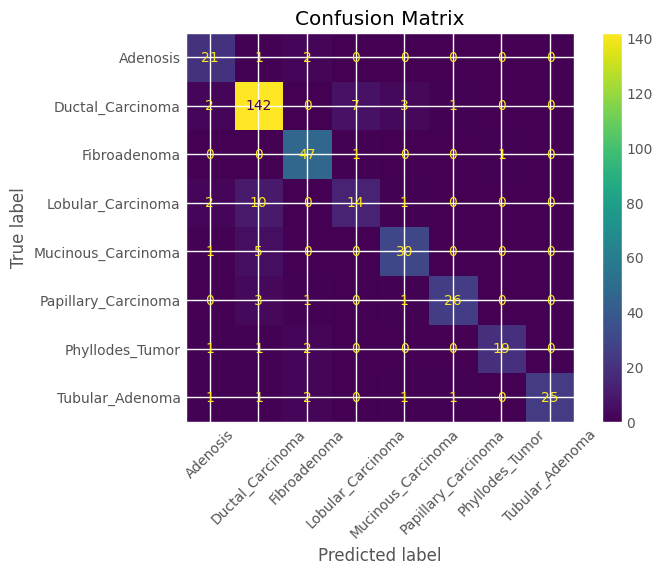

In [23]:
from sklearn.neighbors import KNeighborsClassifier

# Initialize and train the KNN model
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train, y_train)

# Make predictions
y_pred_knn = knn_model.predict(X_test)

# Evaluate the model
print("KNN Accuracy:", accuracy_score(y_test, y_pred_knn))
print("KNN Classification Report:\n", classification_report(y_test, y_pred_knn))
plot_confusion_matrix(knn_model, X_test, y_test, label_encoder)

XGBoost Accuracy: 0.8058510638297872
XGBoost Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.71      0.76        24
           1       0.77      0.96      0.86       155
           2       0.81      0.80      0.80        49
           3       0.72      0.48      0.58        27
           4       0.83      0.69      0.76        36
           5       0.96      0.71      0.81        31
           6       0.88      0.65      0.75        23
           7       0.88      0.74      0.81        31

    accuracy                           0.81       376
   macro avg       0.83      0.72      0.77       376
weighted avg       0.81      0.81      0.80       376



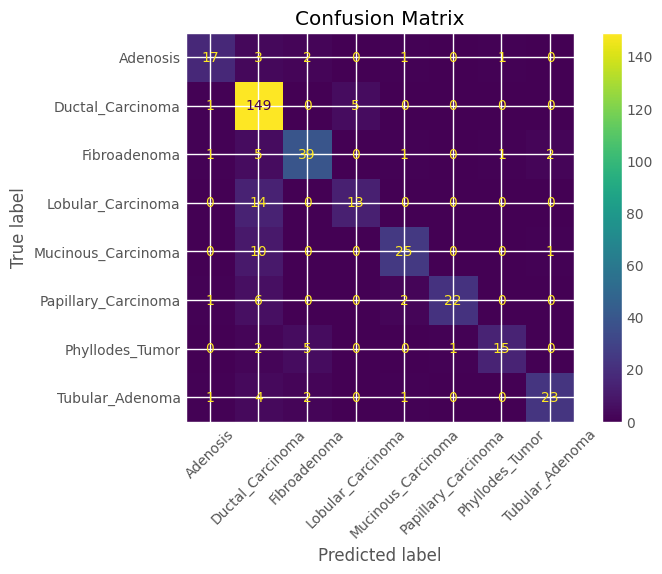

In [24]:
import xgboost as xgb
from sklearn.metrics import accuracy_score

# Initialize and train the XGBoost model
xgb_model = xgb.XGBClassifier(n_estimators=100, random_state=42)
xgb_model.fit(X_train, y_train)

# Make predictions
y_pred_xgb = xgb_model.predict(X_test)

# Evaluate the model
print("XGBoost Accuracy:", accuracy_score(y_test, y_pred_xgb))
print("XGBoost Classification Report:\n", classification_report(y_test, y_pred_xgb))
plot_confusion_matrix(xgb_model, X_test, y_test, label_encoder)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.018876 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 97920
[LightGBM] [Info] Number of data points in the train set: 7137, number of used features: 384
[LightGBM] [Info] Start training from score -2.886596
[LightGBM] [Info] Start training from score -0.826498
[LightGBM] [Info] Start training from score -2.055217
[LightGBM] [Info] Start training from score -2.530926
[LightGBM] [Info] Start training from score -2.299368
[LightGBM] [Info] Start training from score -2.656442
[LightGBM] [Info] Start training from score -2.864235
[LightGBM] [Info] Start training from score -2.638637
LightGBM Accuracy: 0.8031914893617021
LightGBM Classification Report:
               precision    recall  f1-score   support

           0       0.84      0.67      0.74        24
           1       0.76      0.97      0.85       155
           2       0.81      0.90      0.85 

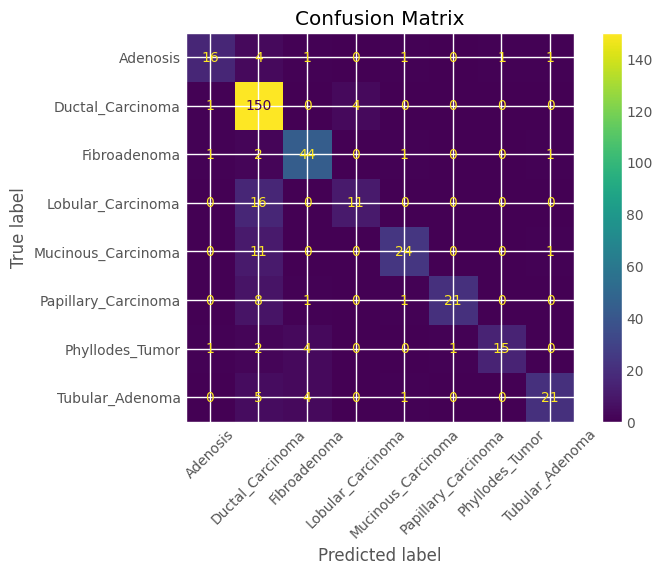

In [25]:
import lightgbm as lgb
from sklearn.metrics import accuracy_score

# Initialize and train the LightGBM model
lgb_model = lgb.LGBMClassifier(n_estimators=100, random_state=42)
lgb_model.fit(X_train, y_train)

# Make predictions
y_pred_lgb = lgb_model.predict(X_test)

# Evaluate the model
print("LightGBM Accuracy:", accuracy_score(y_test, y_pred_lgb))
print("LightGBM Classification Report:\n", classification_report(y_test, y_pred_lgb))
plot_confusion_matrix(lgb_model, X_test, y_test, label_encoder)

MLP Accuracy: 0.9202127659574468
MLP Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.92      0.88        24
           1       0.92      0.93      0.92       155
           2       0.96      0.96      0.96        49
           3       0.75      0.78      0.76        27
           4       0.92      0.92      0.92        36
           5       1.00      0.90      0.95        31
           6       0.96      0.96      0.96        23
           7       1.00      0.94      0.97        31

    accuracy                           0.92       376
   macro avg       0.92      0.91      0.91       376
weighted avg       0.92      0.92      0.92       376



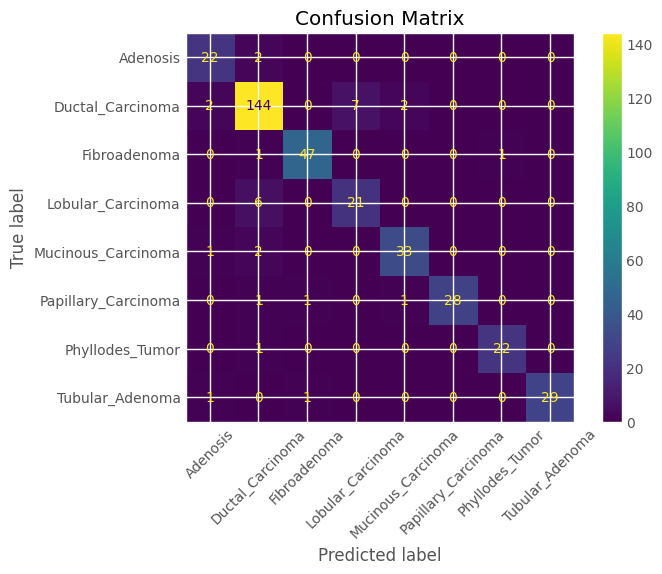

In [26]:
from sklearn.neural_network import MLPClassifier

# Initialize and train the MLP Classifier
mlp_model = MLPClassifier(hidden_layer_sizes=(100,), max_iter=500, random_state=42)
mlp_model.fit(X_train, y_train)

# Make predictions
y_pred_mlp = mlp_model.predict(X_test)

# Evaluate the model
print("MLP Accuracy:", accuracy_score(y_test, y_pred_mlp))
print("MLP Classification Report:\n", classification_report(y_test, y_pred_mlp))
plot_confusion_matrix(mlp_model, X_test, y_test, label_encoder)

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import cross_val_score
import pandas as pd

# Define models
models = {
    'Logistic Regression': logistic_model,
    'Random Forest': rf_model,
    'SVM': svm_model,
    'KNN': knn_model,
    'XGBoost': xgb_model,
    'LightGBM': lgb_model,
    'MLP Classifier': mlp_model
}

# Perform cross-validation
cv_results = []
cv_folds = 5  # Number of folds for cross-validation

for model_name, model in models.items():
    try:
        scores = cross_val_score(model, X_train, y_train, cv=cv_folds, scoring='accuracy')
        for score in scores:  # Collect individual fold scores for boxplot
            cv_results.append({'Model': model_name, 'Fold Accuracy': score})
    except Exception as e:
        print(f"Error with model {model_name}: {e}")

# Convert results to a DataFrame for visualization
cv_results_df = pd.DataFrame(cv_results)

/opt/conda/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/opt/conda/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.015347 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 97920
[LightGBM] [Info] Number of data points in the train set: 5709, number of used features: 384
[LightGBM] [Info] Start training from score -2.887748
[LightGBM] [Info] Start training from score -0.826553
[LightGBM] [Info] Start training from score -2.055386
[LightGBM] [Info] Start training from score -2.529502
[LightGBM] [Info] Start training from score -2.300660
[LightGBM] [Info] Start training from score -2.655838
[LightGBM] [Info] Start training from score -2.862902
[LightGBM] [Info] Start training from score -2.638532
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.014663 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 97920
[LightGBM] [Info] Number of data points in the train set: 5709, number of used fe

In [28]:
cv_results_df

,Model,Fold Accuracy
0,Logistic Regression,0.835434
1,Logistic Regression,0.832633
2,Logistic Regression,0.850736
3,Logistic Regression,0.845830
4,Logistic Regression,0.844429
5,Random Forest,0.693978
6,Random Forest,0.692577
7,Random Forest,0.712684
8,Random Forest,0.699369
9,Random Forest,0.693062


In [29]:
# Grouped metrics for bar plot
summary_df = cv_results_df.groupby('Model')['Fold Accuracy'].agg(
    Mean_Accuracy='mean', Std_Accuracy='std'
).reset_index()

In [30]:
summary_df

,Model,Mean_Accuracy,Std_Accuracy
0,KNN,0.854841,0.006808
1,LightGBM,0.817714,0.011387
2,Logistic Regression,0.841812,0.007543
3,MLP Classifier,0.891553,0.007939
4,Random Forest,0.698334,0.008469
5,SVM,0.851481,0.010848
6,XGBoost,0.818554,0.010801


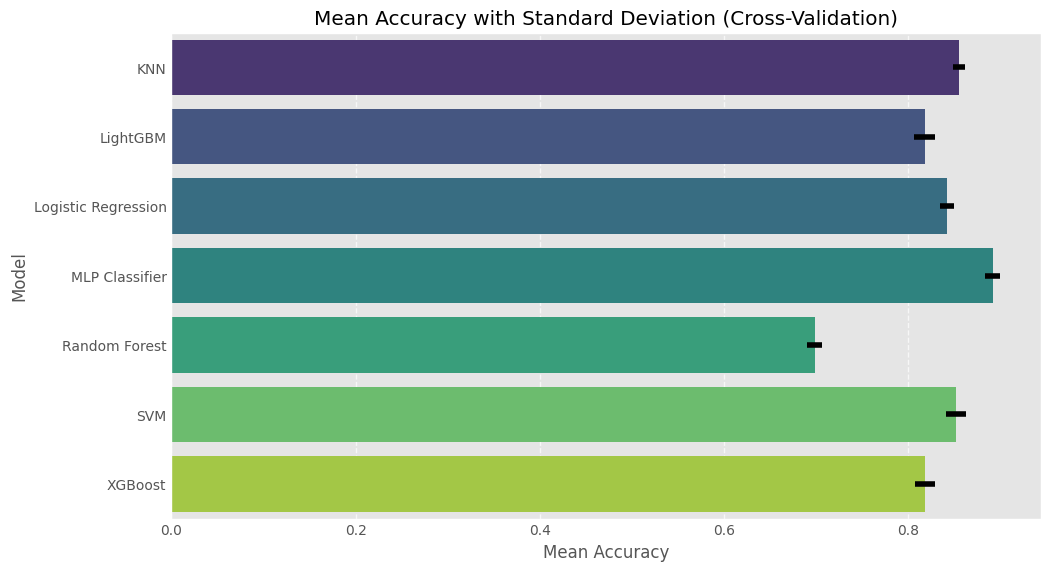

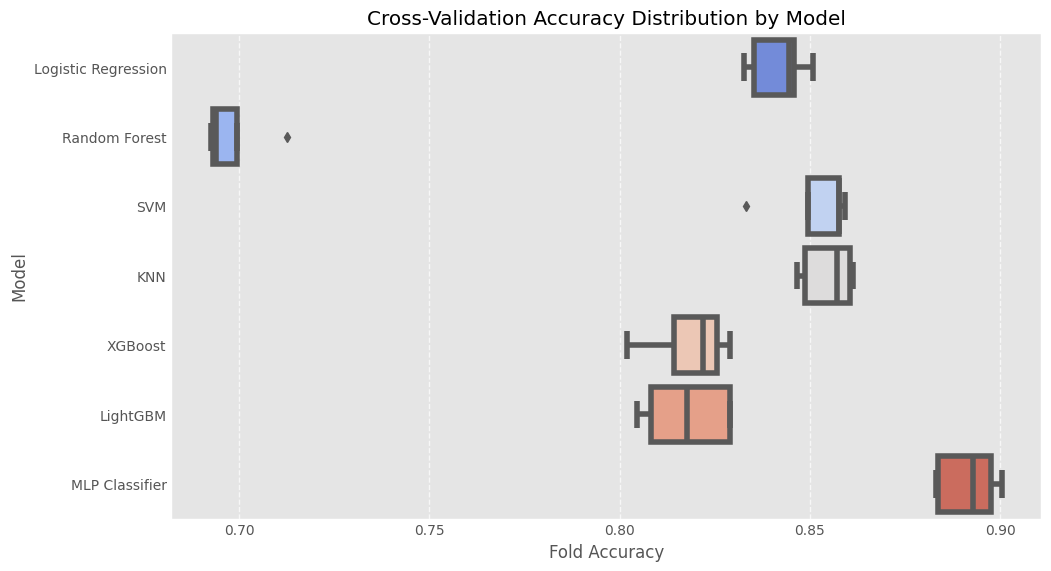

In [31]:
plt.figure(figsize=(10, 6))
sns.barplot(
    data=summary_df,
    x='Mean_Accuracy',
    y='Model',
    xerr=summary_df['Std_Accuracy'],
    palette='viridis'
)
plt.title('Mean Accuracy with Standard Deviation (Cross-Validation)')
plt.xlabel('Mean Accuracy')
plt.ylabel('Model')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

plt.figure(figsize=(10, 6))
sns.boxplot(
    data=cv_results_df,
    x='Fold Accuracy',
    y='Model',
    palette='coolwarm'
)
plt.title('Cross-Validation Accuracy Distribution by Model')
plt.xlabel('Fold Accuracy')
plt.ylabel('Model')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

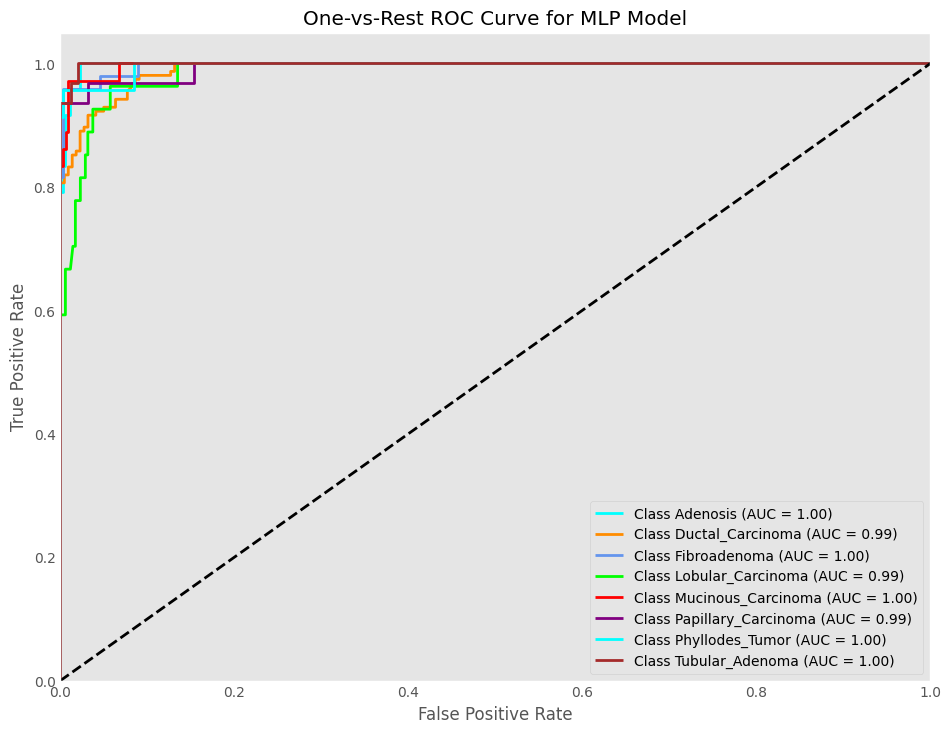

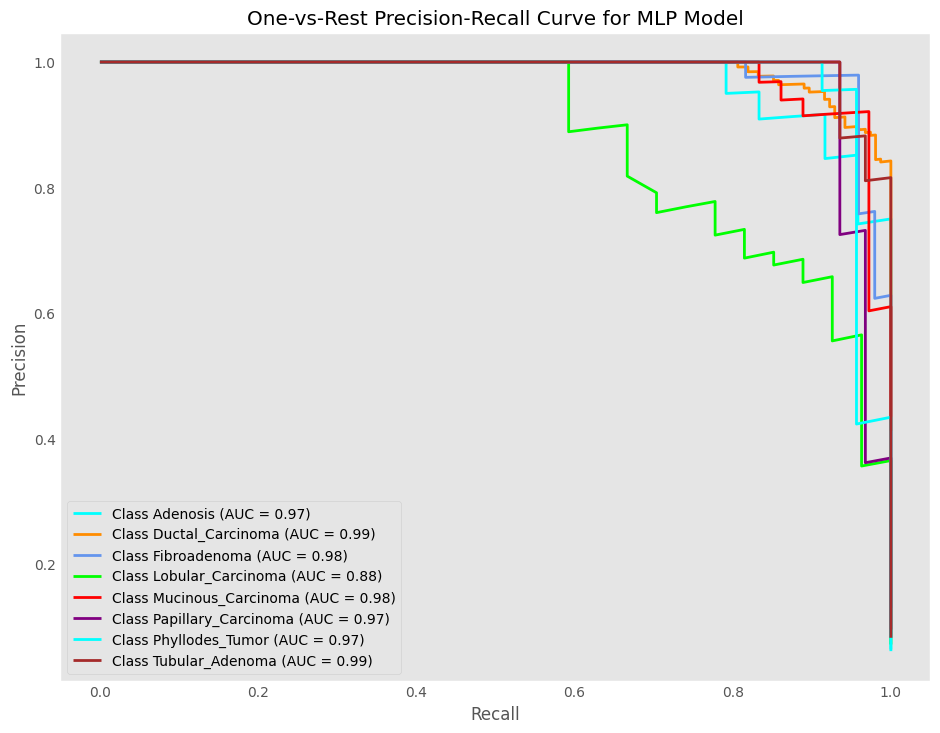

In [32]:
from sklearn.metrics import roc_curve, auc, precision_recall_curve
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt
from itertools import cycle

from sklearn.neural_network import MLPClassifier

mlp_model = MLPClassifier(hidden_layer_sizes=(100,), max_iter=500, random_state=42)
mlp_model.fit(X_train, y_train)

# Binarize the labels (One-vs-Rest strategy)
y_test_binarized = label_binarize(y_test, classes=range(len(label_encoder.classes_)))
n_classes = y_test_binarized.shape[1]

# Get probabilities for each class
y_score = mlp_model.predict_proba(X_test)

# Compute ROC and Precision-Recall for each class
fpr = {}
tpr = {}
roc_auc = {}
precision = {}
recall = {}
pr_auc = {}

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_binarized[:, i], y_score[:, i])
    precision[i], recall[i], _ = precision_recall_curve(y_test_binarized[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])
    pr_auc[i] = auc(recall[i], precision[i])


plt.figure(figsize=(10, 8))
colors = cycle(['aqua', 'darkorange', 'cornflowerblue', 'lime', 'red', 'purple', 'cyan', 'brown'])
for i, color in zip(range(n_classes), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label=f'Class {label_encoder.classes_[i]} (AUC = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('One-vs-Rest ROC Curve for MLP Model')
plt.legend(loc="lower right")
plt.grid()
plt.show()

# Plot Precision-Recall Curve for each class
plt.figure(figsize=(10, 8))
for i, color in zip(range(n_classes), colors):
    plt.plot(recall[i], precision[i], color=color, lw=2,
             label=f'Class {label_encoder.classes_[i]} (AUC = {pr_auc[i]:.2f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('One-vs-Rest Precision-Recall Curve for MLP Model')
plt.legend(loc="lower left")
plt.grid()
plt.show()

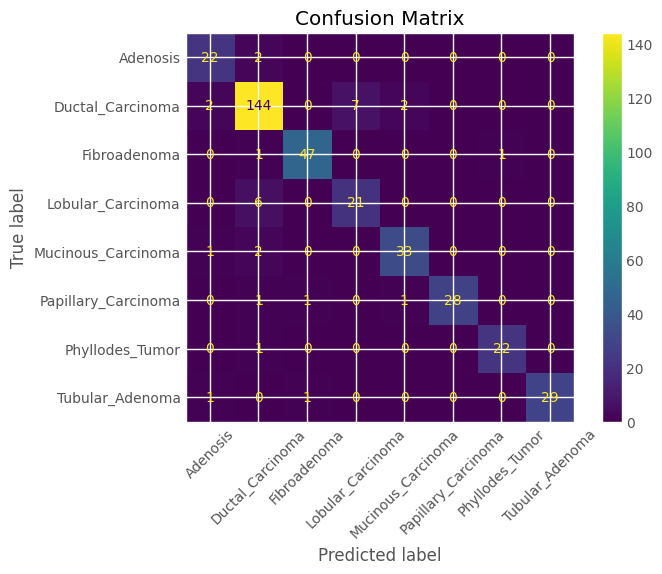

In [33]:
plot_confusion_matrix(mlp_model, X_test, y_test, label_encoder)

## Optimising the MLP to train it with the best parameters

In [34]:
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import classification_report, accuracy_score
import numpy as np

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.05, random_state=42, stratify=y
)


mlp = MLPClassifier(max_iter=1000, random_state=42)

# Define the hyperparameter grid
param_grid = {
    'hidden_layer_sizes': [(50,), (100,), (100, 50), (150, 100, 50)],
    'activation': ['relu', 'tanh', 'logistic'],
    'solver': ['adam', 'sgd'],
    'alpha': [0.0001, 0.001, 0.01],
    'learning_rate': ['constant', 'adaptive']
}

# Initialize GridSearchCV
grid_search = GridSearchCV(
    estimator=mlp,
    param_grid=param_grid,
    scoring='accuracy',
    cv=5,
    verbose=2,
    n_jobs=-1
)

# Perform the grid search
grid_search.fit(X_train, y_train)

# Get the best parameters and the best estimator
best_params = grid_search.best_params_
best_model = grid_search.best_estimator_

print("Best Hyperparameters:", best_params)

Fitting 5 folds for each of 144 candidates, totalling 720 fits


/opt/conda/lib/python3.10/site-packages/joblib/externals/loky/backend/fork_exec.py:38: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid = os.fork()
/opt/conda/lib/python3.10/site-packages/joblib/externals/loky/backend/fork_exec.py:38: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid = os.fork()


[CV] END activation=relu, alpha=0.0001, hidden_layer_sizes=(50,), learning_rate=constant, solver=adam; total time=   5.5s
[CV] END activation=relu, alpha=0.0001, hidden_layer_sizes=(50,), learning_rate=constant, solver=sgd; total time=  24.0s
[CV] END activation=relu, alpha=0.0001, hidden_layer_sizes=(50,), learning_rate=adaptive, solver=adam; total time=   4.7s
[CV] END activation=relu, alpha=0.0001, hidden_layer_sizes=(50,), learning_rate=adaptive, solver=adam; total time=   5.1s
[CV] END activation=relu, alpha=0.0001, hidden_layer_sizes=(50,), learning_rate=adaptive, solver=sgd; total time=  24.4s
[CV] END activation=relu, alpha=0.0001, hidden_layer_sizes=(100,), learning_rate=constant, solver=adam; total time=   5.0s
[CV] END activation=relu, alpha=0.0001, hidden_layer_sizes=(100,), learning_rate=constant, solver=adam; total time=   4.8s
[CV] END activation=relu, alpha=0.0001, hidden_layer_sizes=(100,), learning_rate=constant, solver=adam; total time=   8.2s
[CV] END activation=rel

/opt/conda/lib/python3.10/site-packages/sklearn/neural_network/_multilayer_perceptron.py:686: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/neural_network/_multilayer_perceptron.py:686: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/neural_network/_multilayer_perceptron.py:686: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/neural_network/_multilayer_perceptron.py:686: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/neural_network/_multilayer_perce

[CV] END activation=relu, alpha=0.01, hidden_layer_sizes=(150, 100, 50), learning_rate=adaptive, solver=sgd; total time=  33.8s
[CV] END activation=tanh, alpha=0.0001, hidden_layer_sizes=(50,), learning_rate=constant, solver=sgd; total time=  27.2s
[CV] END activation=tanh, alpha=0.0001, hidden_layer_sizes=(50,), learning_rate=adaptive, solver=adam; total time=   7.9s
[CV] END activation=tanh, alpha=0.0001, hidden_layer_sizes=(50,), learning_rate=adaptive, solver=sgd; total time=  31.7s
[CV] END activation=tanh, alpha=0.0001, hidden_layer_sizes=(100,), learning_rate=constant, solver=adam; total time=   6.5s
[CV] END activation=tanh, alpha=0.0001, hidden_layer_sizes=(100,), learning_rate=constant, solver=adam; total time=   9.2s
[CV] END activation=tanh, alpha=0.0001, hidden_layer_sizes=(100,), learning_rate=constant, solver=sgd; total time=  34.7s
[CV] END activation=tanh, alpha=0.0001, hidden_layer_sizes=(100,), learning_rate=adaptive, solver=adam; total time=   7.4s
[CV] END activati

...

[CV] END activation=tanh, alpha=0.0001, hidden_layer_sizes=(100,), learning_rate=adaptive, solver=adam; total time=   8.6s
[CV] END activation=tanh, alpha=0.0001, hidden_layer_sizes=(100,), learning_rate=adaptive, solver=sgd; total time=  37.6s
[CV] END activation=tanh, alpha=0.0001, hidden_layer_sizes=(100, 50), learning_rate=constant, solver=adam; total time=   7.8s
[CV] END activation=tanh, alpha=0.0001, hidden_layer_sizes=(100, 50), learning_rate=constant, solver=adam; total time=   7.6s
[CV] END activation=tanh, alpha=0.0001, hidden_layer_sizes=(100, 50), learning_rate=constant, solver=sgd; total time=  32.3s
[CV] END activation=tanh, alpha=0.0001, hidden_layer_sizes=(100, 50), learning_rate=adaptive, solver=adam; total time=   8.1s
[CV] END activation=tanh, alpha=0.0001, hidden_layer_sizes=(100, 50), learning_rate=adaptive, solver=adam; total time=   7.4s
[CV] END activation=tanh, alpha=0.0001, hidden_layer_sizes=(100, 50), learning_rate=adaptive, solver=adam; total time=   7.9s


/opt/conda/lib/python3.10/site-packages/sklearn/neural_network/_multilayer_perceptron.py:686: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/neural_network/_multilayer_perceptron.py:686: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/neural_network/_multilayer_perceptron.py:686: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/neural_network/_multilayer_perceptron.py:686: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/neural_network/_multilayer_perce

[CV] END activation=tanh, alpha=0.0001, hidden_layer_sizes=(100,), learning_rate=adaptive, solver=sgd; total time=  38.5s
[CV] END activation=tanh, alpha=0.0001, hidden_layer_sizes=(100, 50), learning_rate=constant, solver=adam; total time=   8.3s
[CV] END activation=tanh, alpha=0.0001, hidden_layer_sizes=(100, 50), learning_rate=constant, solver=sgd; total time=  31.8s
[CV] END activation=tanh, alpha=0.0001, hidden_layer_sizes=(100, 50), learning_rate=adaptive, solver=adam; total time=   6.1s
[CV] END activation=tanh, alpha=0.0001, hidden_layer_sizes=(100, 50), learning_rate=adaptive, solver=adam; total time=   7.6s
[CV] END activation=tanh, alpha=0.0001, hidden_layer_sizes=(100, 50), learning_rate=adaptive, solver=sgd; total time=  36.2s
[CV] END activation=tanh, alpha=0.0001, hidden_layer_sizes=(150, 100, 50), learning_rate=constant, solver=adam; total time=   9.0s
[CV] END activation=tanh, alpha=0.0001, hidden_layer_sizes=(150, 100, 50), learning_rate=constant, solver=adam; total t

/opt/conda/lib/python3.10/site-packages/sklearn/neural_network/_multilayer_perceptron.py:686: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/neural_network/_multilayer_perceptron.py:686: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/neural_network/_multilayer_perceptron.py:686: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/neural_network/_multilayer_perceptron.py:686: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/neural_network/_multilayer_perce

Best Hyperparameters: {'activation': 'relu', 'alpha': 0.001, 'hidden_layer_sizes': (100,), 'learning_rate': 'constant', 'solver': 'adam'}


In [35]:
# Predict using the best model
y_pred = best_model.predict(X_test)

# Evaluate performance
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy on Test Data: {accuracy:.2f}")


Classification Report:
                     precision    recall  f1-score   support

           Adenosis       0.82      0.86      0.84        21
   Ductal_Carcinoma       0.91      0.91      0.91       164
       Fibroadenoma       0.91      0.90      0.91        48
  Lobular_Carcinoma       0.65      0.67      0.66        30
 Mucinous_Carcinoma       0.89      0.89      0.89        38
Papillary_Carcinoma       0.96      0.85      0.90        27
    Phyllodes_Tumor       0.87      0.95      0.91        21
    Tubular_Adenoma       0.89      0.93      0.91        27

           accuracy                           0.88       376
          macro avg       0.86      0.87      0.87       376
       weighted avg       0.88      0.88      0.88       376

Accuracy on Test Data: 0.88


In [69]:
from sklearn.neural_network import MLPClassifier

# Define the best hyperparameters
best_params = {
    'activation': 'relu',
    'alpha': 0.001,
    'hidden_layer_sizes': (100,),
    'learning_rate': 'constant',
    'solver': 'adam'
}

# Initialize the MLP model with the best hyperparameters
optimized_mlp_model = MLPClassifier(**best_params, max_iter=500, random_state=42)

# Train the model on the training data
optimized_mlp_model.fit(X_train, y_train)

print("Optimized MLP model trained successfully!")

Optimized MLP model trained successfully!


In [70]:
# Evaluate on the test set
accuracy = optimized_mlp_model.score(X_test, y_test)
print(f"Test Accuracy of Optimized MLP Model: {accuracy:.4f}")

# Predict the test set
y_pred = optimized_mlp_model.predict(X_test)

Test Accuracy of Optimized MLP Model: 0.8830


In [71]:
print(classification_report(y_test, y_pred))

                     precision    recall  f1-score   support

           Adenosis       0.82      0.86      0.84        21
   Ductal_Carcinoma       0.91      0.91      0.91       164
       Fibroadenoma       0.91      0.90      0.91        48
  Lobular_Carcinoma       0.65      0.67      0.66        30
 Mucinous_Carcinoma       0.89      0.89      0.89        38
Papillary_Carcinoma       0.96      0.85      0.90        27
    Phyllodes_Tumor       0.87      0.95      0.91        21
    Tubular_Adenoma       0.89      0.93      0.91        27

           accuracy                           0.88       376
          macro avg       0.86      0.87      0.87       376
       weighted avg       0.88      0.88      0.88       376



In [44]:
test_df = make_dataframe([test_path])

In [58]:
test_df.head()

,Image Path,Class,Embeddings
0,/kaggle/working/classification_dataset_by_cate...,Tubular_Adenoma,"[-0.8624445, 2.5977619, -0.4979818, 4.547253, ..."
1,/kaggle/working/classification_dataset_by_cate...,Tubular_Adenoma,"[3.1079767, 2.569013, 1.596273, 1.8913381, 1.9..."
2,/kaggle/working/classification_dataset_by_cate...,Tubular_Adenoma,"[0.71525407, 13.173824, -0.5739203, 2.5839672,..."
3,/kaggle/working/classification_dataset_by_cate...,Tubular_Adenoma,"[2.0216742, 0.7736641, 0.5726086, -0.45647067,..."
4,/kaggle/working/classification_dataset_by_cate...,Tubular_Adenoma,"[2.647052, 1.0687795, 0.6040838, 2.2076397, -0..."


In [55]:
len(test_df.iloc[0, 2])

384

In [48]:
test_df_embeddings = add_embeddings_to_dataframe(test_df, 'Image Path', model)

Generating Emebddings: 100%|██████████| 396/396 [00:11<00:00, 35.05image/s]


In [49]:
import joblib

In [72]:
# Save the optimized model
joblib.dump(optimized_mlp_model, "optimized_mlp_model.joblib")
print("Optimized model saved successfully!")

# Save the LabelEncoder
joblib.dump(label_encoder, "label_encoder.joblib")
print("LabelEncoder saved successfully!")

Optimized model saved successfully!
LabelEncoder saved successfully!


In [ ]:
loaded_model = joblib.load('/kaggle/working/optimized_mlp_model.joblib')

In [73]:
import pandas as pd
from tqdm import tqdm

def make_predictions_on_dataframe(df: pd.DataFrame, embedding_col: str, model) -> pd.DataFrame:
    """
    Performs predictions on a dataframe using the embeddings and a trained model.
    
    Args:
        df (pd.DataFrame): The dataframe containing embeddings and other metadata.
        embedding_col (str): The column name where embeddings are stored.
        model: The trained model to use for predictions.
        
    Returns:
        pd.DataFrame: The original dataframe with predictions added as a new column.
    """
    # Initialize a list to store predictions
    predictions = []
    
    # Iterate through embeddings and make predictions
    for embedding in tqdm(df[embedding_col], desc='Generating Predictions', unit='embedding'):
        # Ensure the embedding is reshaped properly for the model
        embedding_reshaped = embedding.reshape(1, -1)  # Reshape to 2D array
        prediction = model.predict(embedding_reshaped)
        predictions.append(prediction[0])  # Append the predicted class
    
    # Add predictions as a new column in the dataframe
    df['Predictions'] = predictions
    return df

In [74]:
optimized_model = joblib.load("optimized_mlp_model.joblib")
label_encoder = joblib.load("label_encoder.joblib")

In [75]:
# Perform inference
test_df_with_predictions = make_predictions_on_dataframe(test_df, embedding_col='Embeddings', model=optimized_model)

Generating Predictions: 100%|██████████| 396/396 [00:00<00:00, 3383.98embedding/s]


In [77]:
test_df_with_predictions.head()

,Image Path,Class,Embeddings,Predictions
0,/kaggle/working/classification_dataset_by_cate...,Tubular_Adenoma,"[-0.8624445, 2.5977619, -0.4979818, 4.547253, ...",Ductal_Carcinoma
1,/kaggle/working/classification_dataset_by_cate...,Tubular_Adenoma,"[3.1079767, 2.569013, 1.596273, 1.8913381, 1.9...",Tubular_Adenoma
2,/kaggle/working/classification_dataset_by_cate...,Tubular_Adenoma,"[0.71525407, 13.173824, -0.5739203, 2.5839672,...",Tubular_Adenoma
3,/kaggle/working/classification_dataset_by_cate...,Tubular_Adenoma,"[2.0216742, 0.7736641, 0.5726086, -0.45647067,...",Tubular_Adenoma
4,/kaggle/working/classification_dataset_by_cate...,Tubular_Adenoma,"[2.647052, 1.0687795, 0.6040838, 2.2076397, -0...",Tubular_Adenoma


Accuracy: 0.91
Classification Report:
                     precision    recall  f1-score   support

           Adenosis       0.90      0.82      0.86        22
   Ductal_Carcinoma       0.92      0.93      0.93       173
       Fibroadenoma       0.90      0.88      0.89        51
  Lobular_Carcinoma       0.74      0.81      0.77        31
 Mucinous_Carcinoma       0.92      0.90      0.91        40
Papillary_Carcinoma       0.90      0.93      0.91        28
    Phyllodes_Tumor       0.96      1.00      0.98        23
    Tubular_Adenoma       1.00      0.89      0.94        28

           accuracy                           0.91       396
          macro avg       0.90      0.89      0.90       396
       weighted avg       0.91      0.91      0.91       396



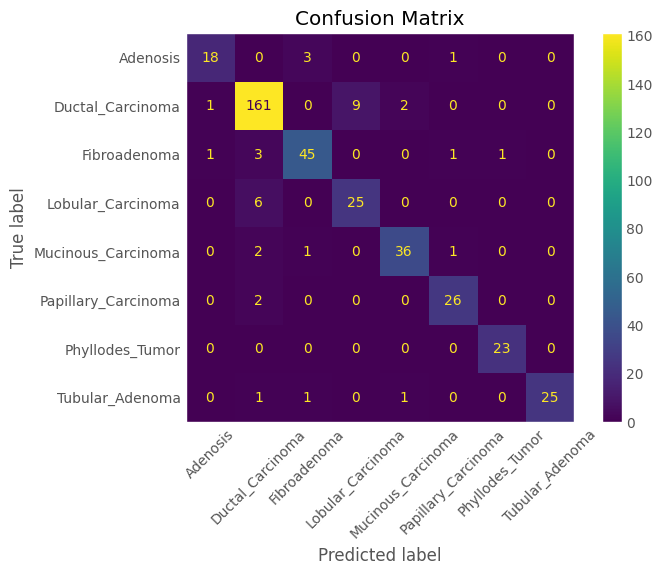

In [80]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# Ensure y_true and y_pred are encoded correctly
y_true_encoded = label_encoder.transform(test_df_with_predictions['Class'])
y_pred_encoded = label_encoder.transform(test_df_with_predictions['Predictions'])

# Accuracy
accuracy = accuracy_score(y_true_encoded, y_pred_encoded)
print(f"Accuracy: {accuracy:.2f}")

# Classification Report
print("Classification Report:")
print(classification_report(y_true_encoded, y_pred_encoded, target_names=label_encoder.classes_))

# Confusion Matrix
conf_matrix = confusion_matrix(y_true_encoded, y_pred_encoded, labels=range(len(label_encoder.classes_)))
disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=label_encoder.classes_)
disp.plot(cmap='viridis', xticks_rotation=45)
plt.title('Confusion Matrix')
plt.grid(False)
plt.show()


In [92]:
def make_predictions_on_one_image(embedding, model):
    """
    Performs predictions on a single image embedding using the trained model and returns
    both the predicted class label and the probabilities for each class.
    
    Args:
        embedding (np.ndarray): The embedding of the image.
        model: The trained model to use for prediction.
        
    Returns:
        tuple: A tuple containing the predicted class label (int or str), 
               a dictionary mapping classes to probabilities, and a raw array of probabilities.
    """
    # Reshape the embedding to match the model's expected input format
    embedding_reshaped = embedding.reshape(1, -1)  # Reshape to (1, n_features)
    
    # Perform prediction
    predicted_class = model.predict(embedding_reshaped)[0]  # Get the predicted class label
    
    # Get prediction probabilities for each class
    probabilities = model.predict_proba(embedding_reshaped)[0]  # Get probabilities for each class
    
    # Map probabilities to class labels
    class_probabilities = {label: prob for label, prob in zip(model.classes_, probabilities)}
    
    # Return the predicted class and probabilities
    return predicted_class, class_probabilities, probabilities


In [93]:
# Example embedding for a single image
example_embedding = test_df.iloc[0,2]  # Assuming you have a list or array of embeddings

# Perform inference
predicted_class, class_probabilities, raw_probabilities = make_predictions_on_one_image(example_embedding, optimized_model)

print(f"Predicted Class: {predicted_class}")
print("Class Probabilities:")
for cls, prob in class_probabilities.items():
    print(f"  Class: {cls}, Probability: {prob:.4f}")

Predicted Class: Ductal_Carcinoma
Class Probabilities:
  Class: Adenosis, Probability: 0.0000
  Class: Ductal_Carcinoma, Probability: 0.8890
  Class: Fibroadenoma, Probability: 0.0005
  Class: Lobular_Carcinoma, Probability: 0.1060
  Class: Mucinous_Carcinoma, Probability: 0.0000
  Class: Papillary_Carcinoma, Probability: 0.0000
  Class: Phyllodes_Tumor, Probability: 0.0000
  Class: Tubular_Adenoma, Probability: 0.0045


In [101]:
import os
import random
import shutil
import tarfile

def create_random_sample_zip(source_dir, output_file, sample_size=10):
    # Temporary directory to store the sampled files
    temp_dir = "temp_sampled"
    os.makedirs(temp_dir, exist_ok=True)
    
    try:
        # Iterate over all subdirectories in the source directory
        for folder_name in os.listdir(source_dir):
            folder_path = os.path.join(source_dir, folder_name)
            if not os.path.isdir(folder_path):
                continue  # Skip files, only process directories
            
            # Get all files in the folder
            all_files = [
                f for f in os.listdir(folder_path) 
                if os.path.isfile(os.path.join(folder_path, f))
            ]
            
            # Randomly sample files
            sampled_files = random.sample(all_files, min(sample_size, len(all_files)))
            
            # Create the corresponding folder in the temp directory
            temp_folder_path = os.path.join(temp_dir, folder_name)
            os.makedirs(temp_folder_path, exist_ok=True)
            
            # Copy sampled files to the temp directory
            for file_name in sampled_files:
                src_file_path = os.path.join(folder_path, file_name)
                dest_file_path = os.path.join(temp_folder_path, file_name)
                shutil.copy2(src_file_path, dest_file_path)
        
        # Create a tar.gz archive of the sampled files
        with tarfile.open(output_file, "w:gz") as tar:
            tar.add(temp_dir, arcname=os.path.basename(temp_dir))
        
        print(f"Sampled images archived into {output_file}")
    finally:
        # Clean up the temporary directory
        shutil.rmtree(temp_dir)

source_directory = "/kaggle/working/classification_dataset_by_category/test"
output_archive = "test_sample.tar.gz"
create_random_sample_zip(source_directory, output_archive)

Sampled images archived into test_sample.tar.gz


In [103]:
import os
import numpy as np
from PIL import Image
import tensorflow as tf
from huggingface_hub import from_pretrained_keras, login
from dotenv import load_dotenv
import joblib
from pathlib import Path

class ImagePredictionPipeline:
    def __init__(self, hf_model_path: str, joblib_model_path: str):
        """
        Initializes the prediction pipeline.

        Args:
            hf_model_path (str): Path to the Hugging Face model on the Hub.
            joblib_model_path (str): Path to the joblib model for classification.
        """
        self.hf_model_path = hf_model_path
        self.joblib_model_path = joblib_model_path
        self.hf_model = self._load_huggingface_model()
        self.joblib_model = self._load_joblib_model()

    def _load_huggingface_model(self) -> tf.keras.Model:
        """Loads the Hugging Face model."""
        print("Loading Hugging Face model...")
        return from_pretrained_keras(self.hf_model_path, compile=False, return_full_path=True)

    def _load_joblib_model(self):
        """Loads the classification model saved with joblib."""
        print("Loading joblib model...")
        return joblib.load(self.joblib_model_path)

    @staticmethod
    def preprocess_image(image_path: str) -> np.ndarray:
        """
        Preprocesses an image for embedding generation.

        Args:
            image_path (str): Path to the image file.

        Returns:
            np.ndarray: Preprocessed image as a 4D tensor.
        """
        try:
            image = Image.open(image_path).convert("RGB")
            image = image.resize((224, 224))
            image_array = np.array(image) / 255.0
            return np.expand_dims(image_array, axis=0)  # Add batch dimension
        except Exception as e:
            raise ValueError(f"Error processing image {image_path}: {e}")

    def generate_embedding(self, image_path: str) -> np.ndarray:
        """
        Generates an embedding for a single image.

        Args:
            image_path (str): Path to the image file.

        Returns:
            np.ndarray: Generated embedding.
        """
        preprocessed_image = self.preprocess_image(image_path)
        try:
            result = self.hf_model.signatures['serving_default'](
                tf.constant(preprocessed_image, dtype=tf.float32)
            )
            return result['output_0'].numpy().flatten()  # Flatten to 1D
        except Exception as e:
            raise ValueError(f"Error generating embedding for image {image_path}: {e}")

    def predict(self, image_path: str):
        """
        Predicts the class and probabilities for a given image.

        Args:
            image_path (str): Path to the image file.

        Returns:
            tuple: Predicted class label, class-probability mapping, raw probabilities.
        """
        # Generate embedding
        embedding = self.generate_embedding(image_path)
        embedding_reshaped = embedding.reshape(1, -1)  # Reshape for the model

        # Perform prediction
        predicted_class = self.joblib_model.predict(embedding_reshaped)[0]
        probabilities = self.joblib_model.predict_proba(embedding_reshaped)[0]

        # Map class labels to probabilities
        class_probabilities = {
            label: prob for label, prob in zip(self.joblib_model.classes_, probabilities)
        }

        return predicted_class, class_probabilities, probabilities

# Initialize the pipeline
pipeline = ImagePredictionPipeline(
    hf_model_path='google/path-foundation',
    joblib_model_path='optimized_mlp_model.joblib'
)

# Example usage
image_path = '/kaggle/working/classification_dataset_by_category/test/ductal_carcinoma/SOB_M_DC-14-10926-200-001.png'
predicted_class, class_probabilities, raw_probabilities = pipeline.predict(image_path)

print(f"Predicted Class: {predicted_class}")
print("Class Probabilities:")
for cls, prob in class_probabilities.items():
    print(f"  Class: {cls}, Probability: {prob:.4f}")

Loading Hugging Face model...


Fetching 8 files:   0%|          | 0/8 [00:00<?, ?it/s]

Loading joblib model...
Predicted Class: Ductal_Carcinoma
Class Probabilities:
  Class: Adenosis, Probability: 0.0000
  Class: Ductal_Carcinoma, Probability: 1.0000
  Class: Fibroadenoma, Probability: 0.0000
  Class: Lobular_Carcinoma, Probability: 0.0000
  Class: Mucinous_Carcinoma, Probability: 0.0000
  Class: Papillary_Carcinoma, Probability: 0.0000
  Class: Phyllodes_Tumor, Probability: 0.0000
  Class: Tubular_Adenoma, Probability: 0.0000
